In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import os
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm
from scipy.ndimage import zoom
import matplotlib.pyplot as plt
import seaborn as sns
from functions_for_goes import crop_goes_to_latlon_box, convert_radiance_to_brightness_temp
from judge_goes19 import preprocess_data, setup_region_parameters

/home/jmayer/miniconda3/envs/mlenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Manually label a small dataset of GOES images for fine-tuning

## Functions

In [4]:
def load_and_prepare_goes_data(date, time):
    ts = pd.to_datetime(date + time)

    lat_bounds, lon_bounds, times = setup_region_parameters(region='SEP')
    data_dir='/home/jmayer/Object_Data/GOES19/'

    print('.' * 85)
    print(f"Processing date {date} time {time}...")

    # Load and crop GOES data
    print("Loading C11 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C11_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_11_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading C14 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C14_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_14_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading C15 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C15_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_15_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading COD data...")
    with xr.open_dataset(f'{data_dir}/goes19_COD2KMF_{date}_{time}.nc') as ds:
        ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    return ds_11_cropped, ds_14_cropped, ds_15_cropped, ds_COD_cropped

In [5]:
# Replace your matplotlib setup with:
import matplotlib
matplotlib.use('Agg')  # Use non-interactive backend
%matplotlib inline
import json

# Then use the simplified non-interactive labeler
class SimpleGOESLabeler:
    def __init__(self, image_data, scene_params, datetime, cod, class_names, save_path='labeled_goes_data.nc'):
        self.image_data = image_data
        self.scene_params = scene_params
        self.datetime = datetime
        self.cod = cod
        self.class_names = class_names
        self.save_path = save_path
        self.results = []  # List to store labeled data
        self.load_existing_unique_ids()
        self.unique_id = self.create_unique_id()
        
    def load_existing_unique_ids(self):
        """Load existing labels from netCDF file"""
        if os.path.exists(self.save_path):
            with xr.open_dataset(self.save_path) as ds:
                self.existing_unique_ids = ds.unique_id.values
        else:
            self.existing_unique_ids = None

    def create_unique_id(self):
        """Create a unique identifier for the current sample"""
        uid = (f"{pd.to_datetime(self.datetime).strftime('%Y%m%d%H%M')}_"
               f"{self.scene_params['y_idx']}_"
               f"{self.scene_params['x_idx']}")
        return uid

    def check_if_already_labeled(self):
        """Check if a sample with the given unique_id has already been labeled"""
        if self.existing_unique_ids is None:
            return False
        return self.unique_id in self.existing_unique_ids

    def save_labels_to_file(self, label_idx):
        """Save labels to netCDF file with incremental updates"""

        new_ds = xr.Dataset({
            'unique_id': (['sample'], [self.unique_id]),
            'datetime': (['sample'], [pd.to_datetime(self.datetime)]),
            'y_idx': (['sample'], [self.scene_params['y_idx']]),
            'x_idx': (['sample'], [self.scene_params['x_idx']]),
            'lat_mid': (['sample'], [self.scene_params['lat_mid']]),
            'lon_mid': (['sample'], [self.scene_params['lon_mid']]),
            'ice_flag': (['sample'], [self.scene_params['ice_flag']]),
            'label': (['sample'], [label_idx]),
            'class_name': (['sample'], [self.class_names[label_idx]]),
            'image_data': (['sample', 'channel', 'y', 'x'], [self.image_data])
            }, 
            coords={'sample': [self.scene_params['image_idx']]}
        )
        
        # Save or append to file
        if os.path.exists(self.save_path):
            # Load existing and concatenate
            with xr.open_dataset(self.save_path) as existing_ds:
                # Remove existing label for this image if it exists
                if self.check_if_already_labeled():
                    existing_ds.load()
                    existing_ds = existing_ds.where(existing_ds.unique_id != self.unique_id, drop=True)

                combined_ds = xr.concat([existing_ds, new_ds], dim='sample')
                combined_ds.to_netcdf(self.save_path)
        else:
            # Save new file
            new_ds.to_netcdf(self.save_path)
            
        print(f"Saved new label to {self.save_path}")
    
    def display_image_to_label(self, img_idx):
        """Display an image for labeling"""
        fig, axes = plt.subplots(1, 4, figsize=(15, 5))
        
        idx = img_idx
        current_image = self.image_data

        # Display COD channel
        axes[0].imshow(current_image[3], vmax=1, cmap='Greys_r')
        axes[0].set_title('COD Channel')
        axes[0].axis('off')
        
        # Display BT channel
        axes[1].imshow(current_image[2], vmax=1, cmap='Greys')
        axes[1].set_title('BT Ch14')
        axes[1].axis('off')

        # Display RGB composite
        rgb_channels = current_image[0:3]
        rgb_image = np.zeros((128, 128, 3))
        for j in range(3):
            ch = rgb_channels[j]
            rgb_image[:, :, j] = ch
        axes[2].imshow(rgb_image)
        axes[2].set_title('RGB Composite')
        axes[2].axis('off')

        # Show zoomed out COD image for context
        cod = self.cod
        y_idx_not_zoomed = self.scene_params['y_idx']//2
        x_idx_not_zoomed = self.scene_params['x_idx']//2
        img_buffer = 300
        
        y_start = max(0, y_idx_not_zoomed - img_buffer)
        y_end = min(cod.shape[0], y_idx_not_zoomed + img_buffer)
        x_start = max(0, x_idx_not_zoomed - img_buffer)
        x_end = min(cod.shape[1], x_idx_not_zoomed + img_buffer)
        
        axes[3].imshow(cod[y_start:y_end, x_start:x_end], vmax=40, vmin=0, cmap='Greys_r')
        # plot box where image is
        x_box = min(x_idx_not_zoomed-32, img_buffer-32)
        y_box = min(y_idx_not_zoomed-32, img_buffer-32)
        axes[3].plot([x_box, x_box + 64, x_box + 64, x_box, x_box],
                     [y_box, y_box, y_box + 64, y_box + 64, y_box],
                     color='red', linewidth=2)
        axes[3].set_title('COD Context')
        axes[3].axis('off')
        
        # Add title with location info
        lat = self.scene_params['lat_mid']
        lon = self.scene_params['lon_mid']
        title = f"Image #{idx}: Datetime {self.datetime}, Lat {lat:.1f}°, Lon {lon:.1f}°"
        
        # Check if already labeled
        existing_label = self.check_if_already_labeled()         
        if existing_label:
            title += f"\n[Current: {self.class_names[existing_label]}]"
            fig.patch.set_facecolor('lightgreen')
        
        fig.suptitle(title, fontsize=12)
        plt.tight_layout()
        plt.show()
        plt.close()
        
    def label_single_image(self, img_idx):
        """Label a single image interactively"""
        self.display_image_to_label(img_idx)
        
        print("\nClass options:")
        for i, class_name in enumerate(self.class_names):
            print(f"{i}: {class_name}")
        print("s: Skip image")
        print("d: delete label if exists")
        print("q: Quit labeling")
        
        while True:
            try:
                user_input = input(f"\nEnter label for image {img_idx} (0-5 or 's'): ").strip()
                
                if user_input.lower() == 's':
                    print(f"Skipped image {img_idx}")
                    return True
                
                if user_input.lower() == 'q':
                    print('\nQuitting labeling process')
                    return False
                
                if user_input.lower() == 'd':
                    # Remove existing label for this image if it exists
                    if os.path.exists(self.save_path):
                        # Load existing and concatenate
                        with xr.open_dataset(self.save_path) as existing_ds:
                            # Remove existing label for this image if it exists
                            if self.check_if_already_labeled():
                                existing_ds.load()
                                existing_ds = existing_ds.where(existing_ds.unique_id != self.unique_id, drop=True)
                                existing_ds.to_netcdf(self.save_path)
                                print(f"Deleted existing label for image {img_idx}")
                                return True
                            else:
                                print(f"No existing label to delete for image {img_idx}")
                                return True
                    else:
                        print(f"No existing label to delete for image {img_idx}")
                        return True
                
                label_idx = int(user_input)
                if 0 <= label_idx < len(self.class_names):
                    
                    print(f"✓ Image {img_idx}: {self.class_names[label_idx]}")
                    self.save_labels_to_file(label_idx)
                    return True
                else:
                    print("Invalid class number! Enter 0-5")
                    
            except ValueError:
                print("Invalid input! Enter number 0-5 or 's' or 'd' or 'q'")

def create_labeling_session(bt11, bt14, bt15, cod, n_samples=50, random_seed=42):
    """Create a labeling session with random samples from GOES data"""
    np.random.seed(random_seed)
    
    # Preprocess data to get image patches
    all_weirgb, scenes_params = preprocess_data(bt11, bt14, bt15, cod, window_size=128)
    
    # Select random samples
    total_samples = len(all_weirgb)
    if n_samples > total_samples:
        n_samples = total_samples
        
    selected_indices = np.random.choice(total_samples, n_samples, replace=False)
    selected_images = all_weirgb[selected_indices]
    
    # Update scene params for selected samples
    selected_params = {}
    for key in scenes_params.keys():
        selected_params[key] = [scenes_params[key][i] for i in selected_indices]
    
    return selected_images, selected_params


def start_non_interactive_labeling(bt11, bt14, bt15, cod, datetime, n_samples=20, random_seed=42, save_path=None):
    """Start non-interactive labeling session"""
    class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
    
    print("Processing GOES data...")
    images, params = create_labeling_session(bt11, bt14, bt15, cod, n_samples, random_seed)
    print(f"Created {len(images)} image samples")
    
    if save_path is None:
        timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
        save_path = f'goes_labels_{timestamp}.csv'
    
    print(f"Labels will be saved to: {save_path}")
    
    # Process images one by one
    for img_idx in range(len(images)):
        print(f"\n{'='*60}")
        print(f"Image {img_idx + 1}/{len(images)}")
        print(f"{'='*60}")

        params_idx = {key: params[key][img_idx] for key in params.keys()}
        params_idx['image_idx'] = img_idx
        labeler = SimpleGOESLabeler(images[img_idx], params_idx, datetime, cod, class_names, save_path)
        status = labeler.label_single_image(img_idx)
        if status is False:
            break
    
    print(f"\nLabeling session complete! {len(images)} images labeled.")
    return labeler

## Labeling GOES images

In [4]:
# randomly choose pairs of days and times for the labeling
time_list = ['1400', '1600', '1800', '2000', '2200']
day_list = [f'{i:02d}' for i in range(1, 32)]

day_time_pairs = []
for day in day_list:
    for time in time_list:
        day_time_pairs.append((day, time))

# choose randomly 50 paris
total_pairs = len(day_time_pairs)
n_samples = 50
np.random.seed(0)
selected_indices = np.random.choice(total_pairs, n_samples, replace=False)
selected_indices.sort()
selected_day_time_pairs = np.array(day_time_pairs)[selected_indices]
# append random_seed to each pair
selected_day_time_pairs = [(str(day), str(time), 42 + i) for i, (day, time) in enumerate(selected_day_time_pairs)]

In [5]:
selected_day_time_pairs

[('01', '1800', 42),
 ('02', '1800', 43),
 ('02', '2000', 44),
 ('04', '1600', 45),
 ('04', '2000', 46),
 ('04', '2200', 47),
 ('05', '1800', 48),
 ('05', '2200', 49),
 ('06', '1600', 50),
 ('06', '1800', 51),
 ('07', '1400', 52),
 ('07', '2000', 53),
 ('08', '1800', 54),
 ('09', '1400', 55),
 ('09', '2000', 56),
 ('09', '2200', 57),
 ('10', '1400', 58),
 ('11', '1600', 59),
 ('11', '2200', 60),
 ('12', '1600', 61),
 ('12', '2200', 62),
 ('13', '1400', 63),
 ('13', '1600', 64),
 ('15', '1600', 65),
 ('17', '1400', 66),
 ('17', '2000', 67),
 ('18', '1600', 68),
 ('18', '2200', 69),
 ('19', '1400', 70),
 ('19', '2000', 71),
 ('19', '2200', 72),
 ('20', '1400', 73),
 ('20', '1600', 74),
 ('20', '2000', 75),
 ('21', '1600', 76),
 ('21', '1800', 77),
 ('22', '1600', 78),
 ('22', '1800', 79),
 ('22', '2000', 80),
 ('23', '1400', 81),
 ('23', '1600', 82),
 ('24', '2000', 83),
 ('25', '2200', 84),
 ('26', '1600', 85),
 ('28', '1800', 86),
 ('28', '2000', 87),
 ('29', '1600', 88),
 ('30', '1600

20250801 1800
Datetime already exists in labels.

20250802 1800
Datetime already exists in labels.

20250802 2000
Datetime already exists in labels.

20250804 1600
Datetime already exists in labels.

20250804 2000
Datetime already exists in labels.

20250804 2200
Datetime already exists in labels.

20250805 1800
Datetime already exists in labels.

20250805 2200
Datetime already exists in labels.

20250806 1600
Datetime already exists in labels.

20250806 1800
Datetime already exists in labels.

20250807 1400
Datetime already exists in labels.

20250807 2000
Datetime already exists in labels.

20250808 1800
Datetime already exists in labels.

20250809 1400
Datetime already exists in labels.

20250809 2000
Datetime already exists in labels.

20250809 2200
Datetime already exists in labels.

20250810 1400
Datetime already exists in labels.

20250811 1600
Datetime already exists in labels.

20250811 2200
Datetime already exists in labels.

20250812 1600
Datetime already exists in labels.



/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Loading C14 data...


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Loading C15 data...


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'band': 1, 'number_of_harmonization_coefficients': 3, 'num_star_looks': 24})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Loading COD data...


/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:112: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  y_max = min(ds.dims['y'] - 1, y_max + padding)
/home/jmayer/ACI_research/Code/mesoscale_structure/judge_for_goes/functions_for_goes.py:114: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  x_max = min(ds.dims['x'] - 1, x_max + padding)


Original shape: FrozenMappingWarningOnValuesAccess({'y': 5424, 'x': 5424, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Cropped shape: FrozenMappingWarningOnValuesAccess({'y': 1197, 'x': 1094, 'number_of_time_bounds': 2, 'number_of_image_bounds': 2, 'number_of_LZA_bounds': 2, 'number_of_SZA_bounds': 2})
Lat range: -25.56 to -2.29
Lon range: -97.96 to -74.81
Processing GOES data...
Created 10 image samples
Labels will be saved to: labeled_goes_data.nc

Image 1/10


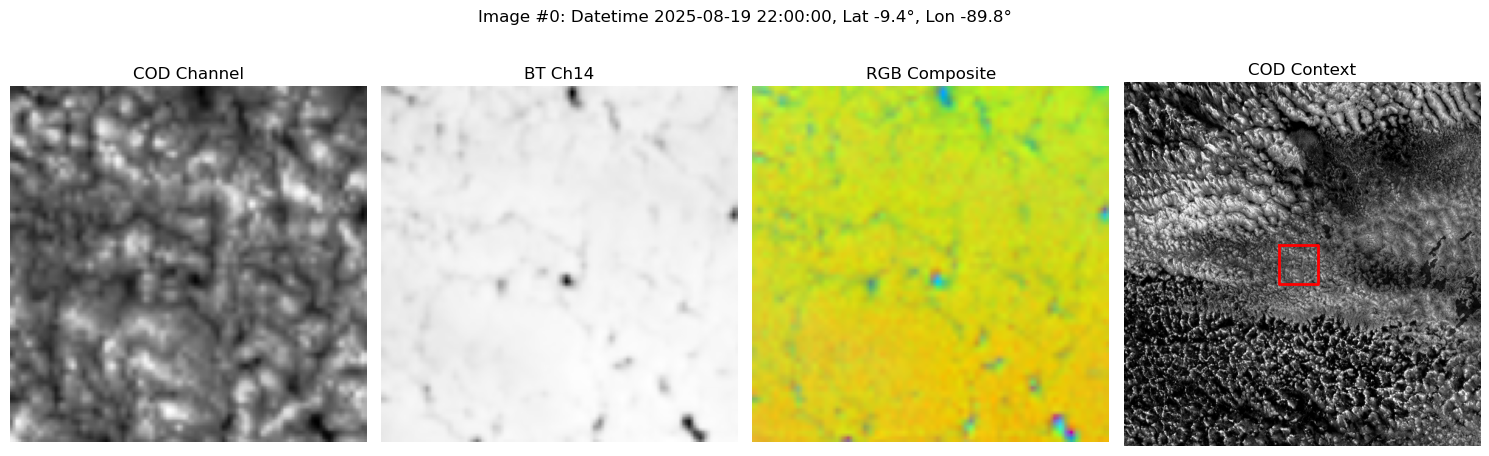


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 0: Closed MCC
Saved new label to labeled_goes_data.nc

Image 2/10


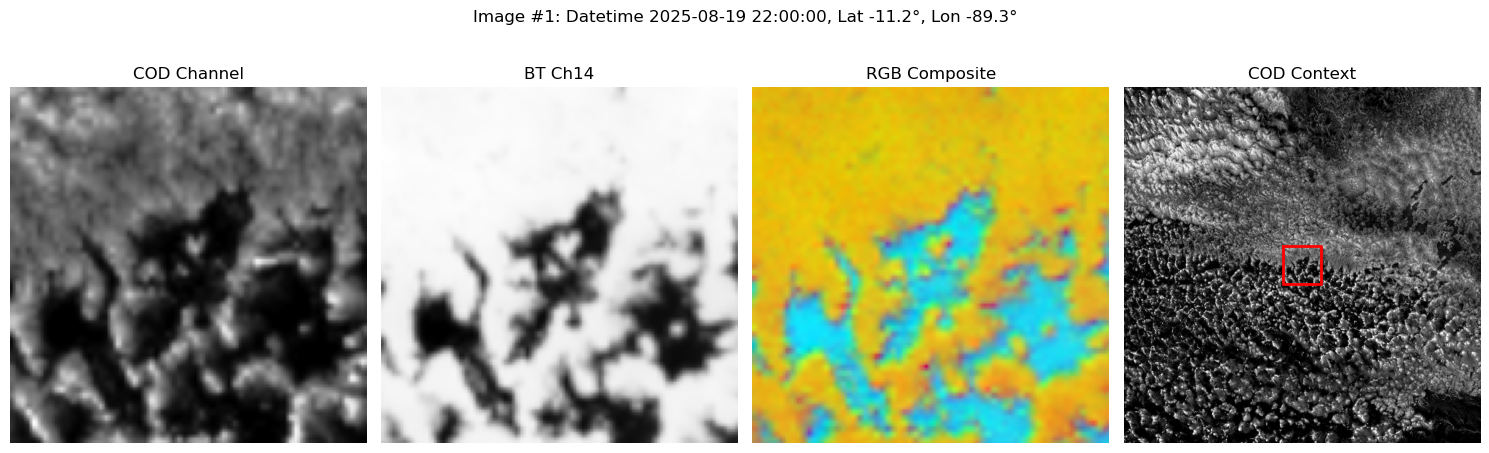


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
Skipped image 1

Image 3/10


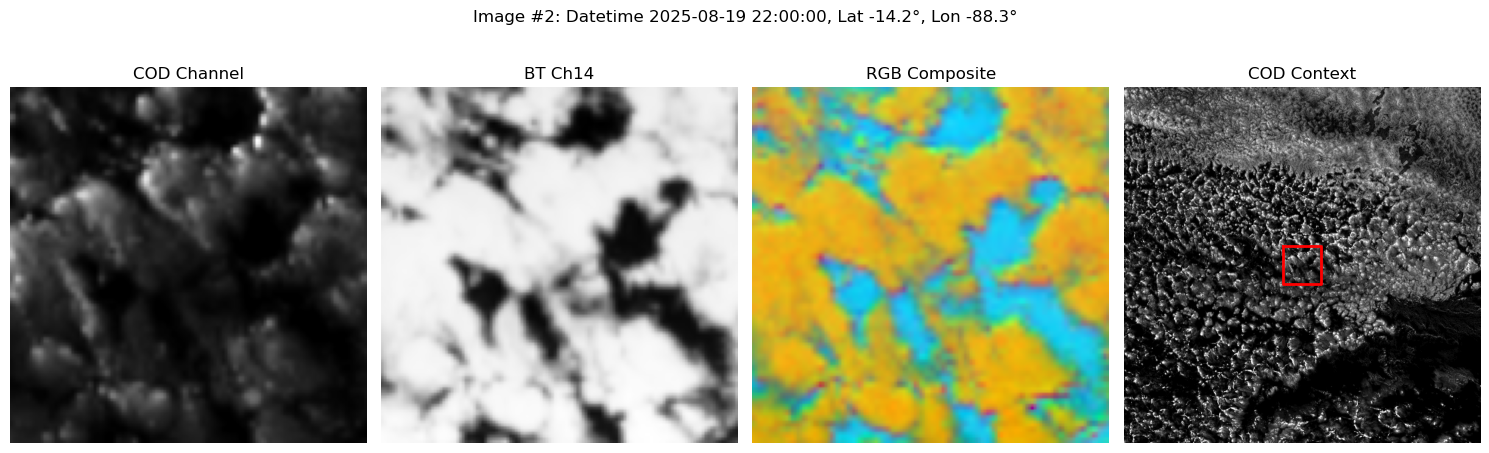


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 2: Disorganized MCC
Saved new label to labeled_goes_data.nc

Image 4/10


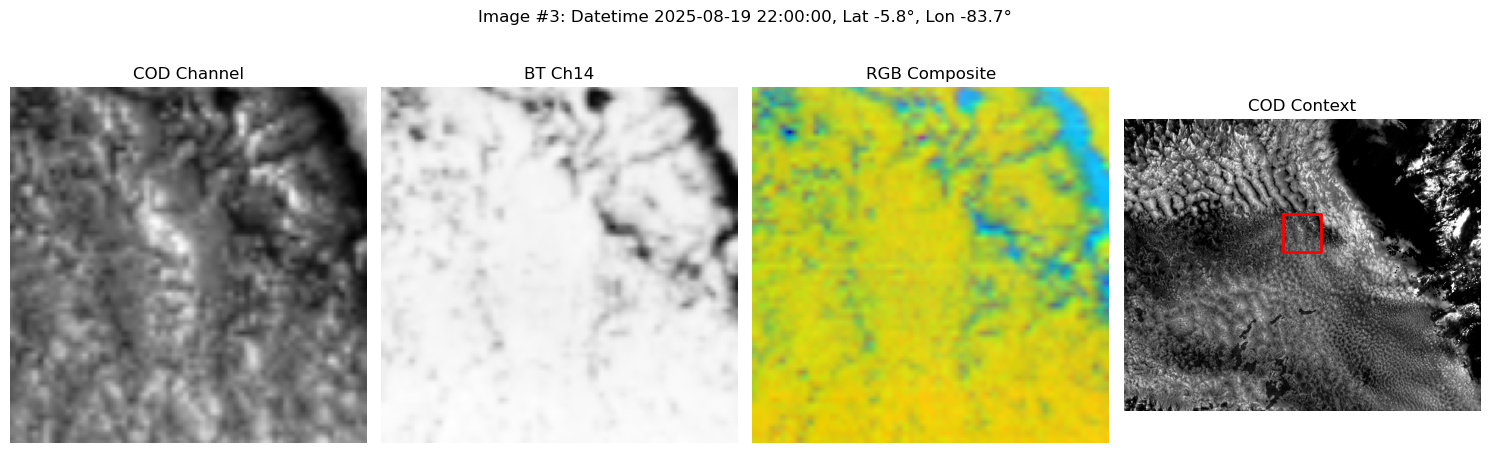


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 3: Closed MCC
Saved new label to labeled_goes_data.nc

Image 5/10


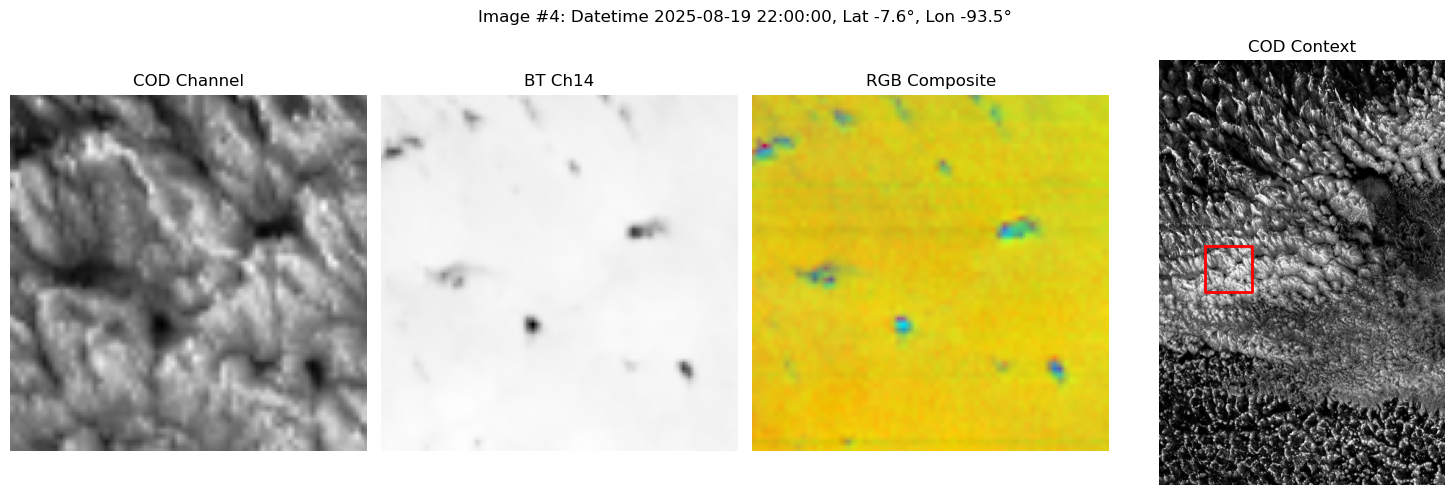


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 4: Closed MCC
Saved new label to labeled_goes_data.nc

Image 6/10


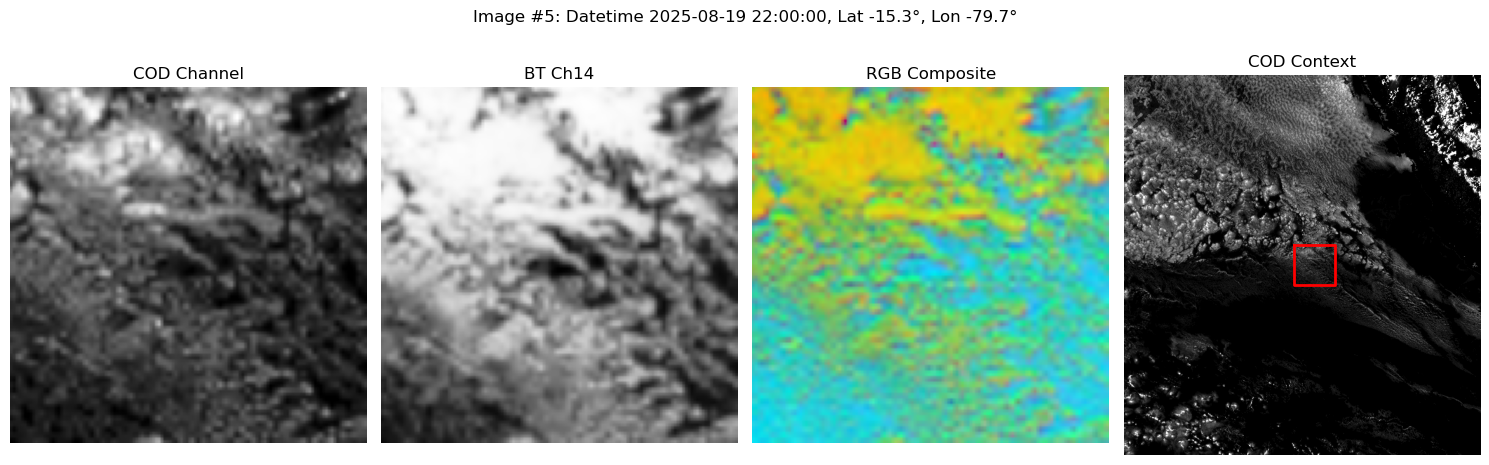


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 5: Solid stratus
Saved new label to labeled_goes_data.nc

Image 7/10


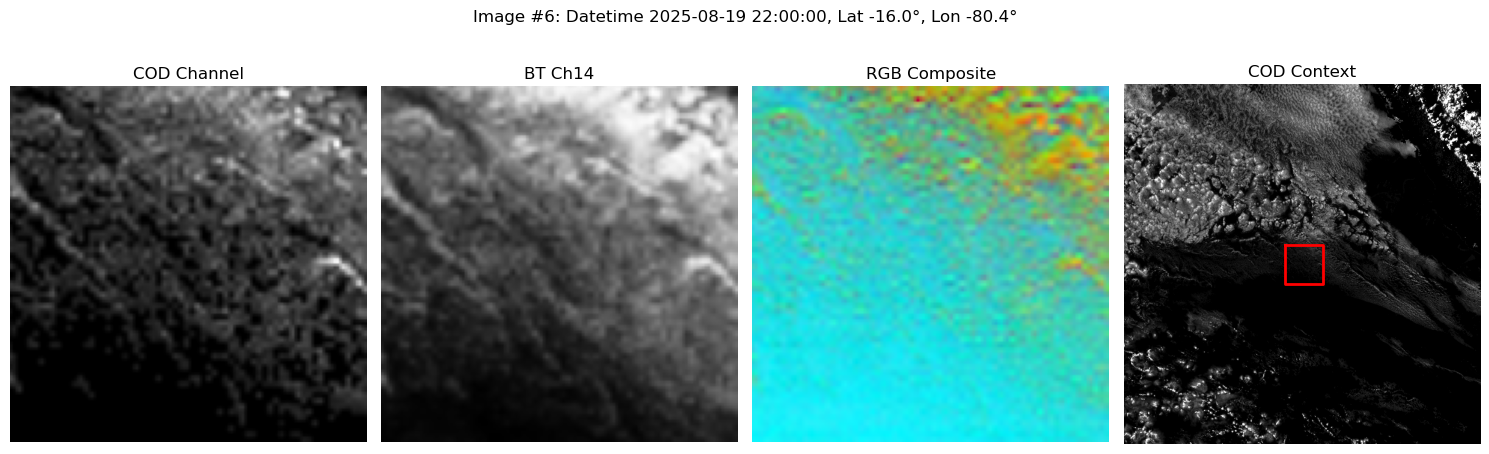


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 6: Solid stratus
Saved new label to labeled_goes_data.nc

Image 8/10


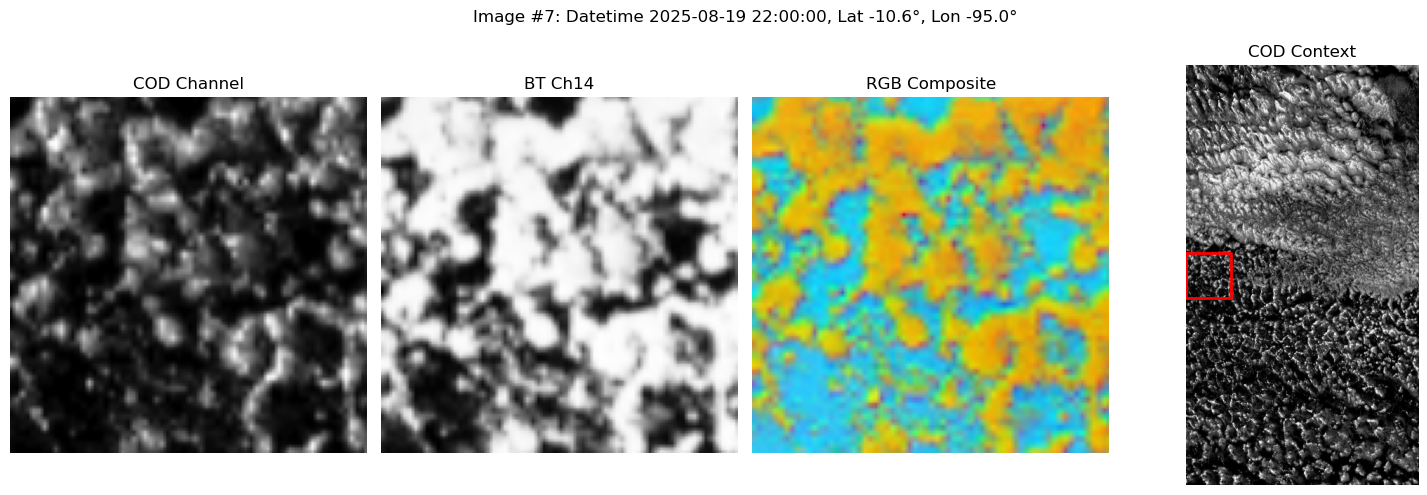


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 7: Solid stratus
Saved new label to labeled_goes_data.nc

Image 9/10


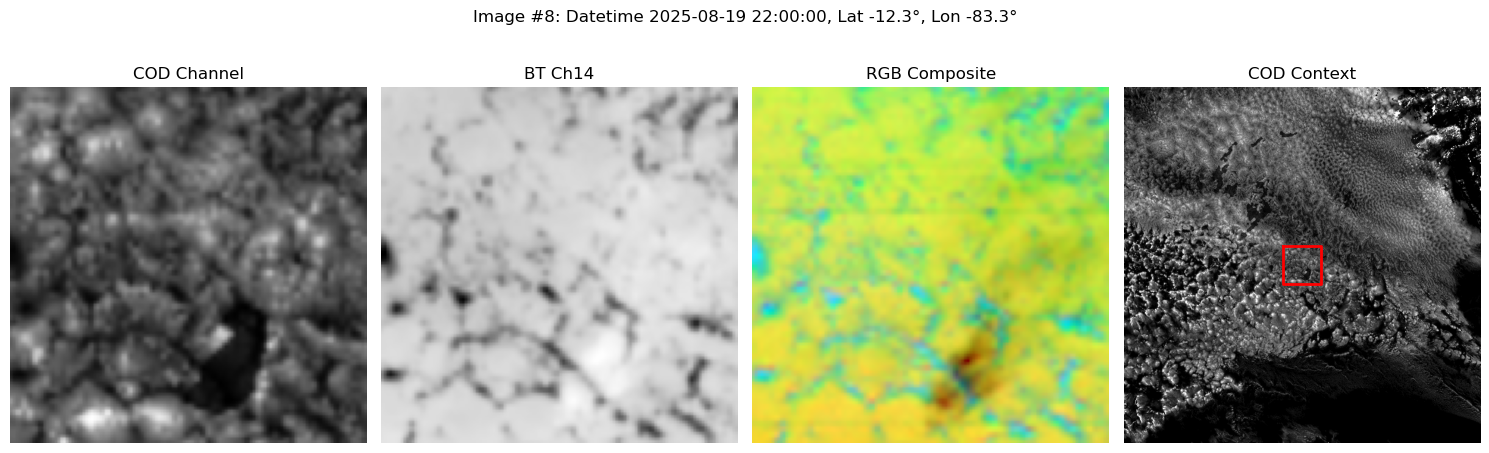


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 8: Closed MCC
Saved new label to labeled_goes_data.nc

Image 10/10


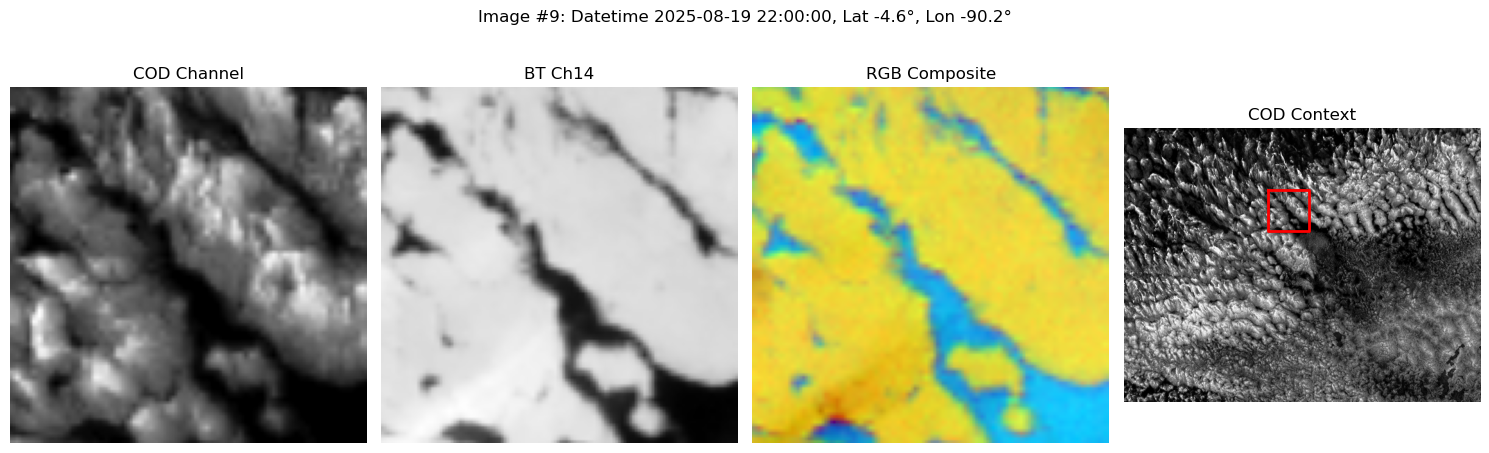


Class options:
0: Solid stratus
1: Closed MCC
2: Open MCC
3: Disorganized MCC
4: Clustered Cu
5: Suppressed Cu
s: Skip image
d: delete label if exists
q: Quit labeling
✓ Image 9: Disorganized MCC
Saved new label to labeled_goes_data.nc

Labeling session complete! 10 images labeled.


In [35]:
save_path='labeled_goes_data.nc'
with xr.open_dataset(save_path) as ds:
    existing_datetimes = np.unique(ds.datetime.values)

for day, time, random_seed in selected_day_time_pairs:
    date='202508' + day
    print(date, time)
    ts = pd.to_datetime(date + time)
    if (pd.to_datetime(existing_datetimes) == ts).any():
        print("Datetime already exists in labels.\n")
        continue
    
    ds_11_cropped, ds_14_cropped, ds_15_cropped, ds_COD_cropped = load_and_prepare_goes_data(date, time)

    labeler = start_non_interactive_labeling(
        ds_11_cropped['BT'], 
        ds_14_cropped['BT'], 
        ds_15_cropped['BT'], 
        ds_COD_cropped['COD'], 
        datetime = pd.to_datetime(date + time),
        n_samples=10,
        random_seed=random_seed,
        save_path=save_path
    )
    break

## Check saved dataset

In [48]:
with xr.open_dataset(save_path) as ds:
    ds.load()
ds

<xarray.Dataset> Size: 120MB
Dimensions:     (sample: 229, channel: 4, y: 128, x: 128)
Coordinates:
  * sample      (sample) int32 916B 0 3 4 6 7 0 4 5 6 7 ... 9 0 2 3 4 5 6 7 8 9
Dimensions without coordinates: channel, y, x
Data variables:
    unique_id   (sample) object 2kB '202508011900_640_1472' ... '202508192200...
    class_name  (sample) object 2kB 'Closed MCC' ... 'Disorganized MCC'
    image_data  (sample, channel, y, x) float64 120MB 0.4903 0.5587 ... 0.0 0.0
    datetime    (sample) datetime64[ns] 2kB 2025-08-01T19:00:00 ... 2025-08-1...
    y_idx       (sample) float64 2kB 640.0 192.0 1.856e+03 ... 1.088e+03 256.0
    x_idx       (sample) float64 2kB 1.472e+03 1.344e+03 ... 1.28e+03 512.0
    lat_mid     (sample) float64 2kB -8.142 -4.043 -19.79 ... -12.32 -4.648
    lon_mid     (sample) float64 2kB -81.36 -82.47 -88.1 ... -83.26 -90.24
    ice_flag    (sample) float64 2kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    label       (sample) float64 2kB 1.0 0.0 5.0 5.0 2.0 ... 0.0 0.0 2.0 1.0 3.0

(array([  9., 110.,  48.,  37.,  15.,  10.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5]),
 <BarContainer object of 6 artists>)

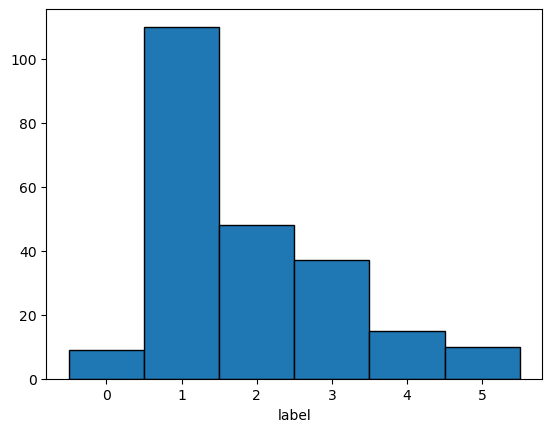

In [53]:
ds.label.plot.hist(bins=np.arange(-0.5, 6.5, 1), edgecolor='black')

In [26]:
for i in range(len(ds.image_data)):
    if np.isnan(ds.image_data[i]).any():
        print(f"Image {i} contains NaN values.")

# Fine-tune judge model for GOES data

In [7]:
class GOESLabeledDataset(Dataset):
    """Dataset for manually labeled GOES images stored in netCDF format"""
    def __init__(self, labeled_netcdf_path):
        self.netcdf_path = labeled_netcdf_path
        
        # Load the netCDF dataset
        with xr.open_dataset(labeled_netcdf_path) as ds:
            # Load data into memory to avoid file access issues
            self.images = ds.image_data.values  # Shape: (n_samples, 4, 128, 128)
            self.labels = ds.label.values       # Shape: (n_samples,)
            self.metadata = {
                'unique_ids': ds.unique_id.values,
                'datetimes': ds.datetime.values,
                'lat_mid': ds.lat_mid.values,
                'lon_mid': ds.lon_mid.values,
                'class_names': ds.class_name.values
            }
        
        print(f"Loaded {len(self.images)} samples from {labeled_netcdf_path}")
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        image = self.images[idx] # Shape: (4, 128, 128)
        label = self.labels[idx]
        
        # Debug checks
        if np.isnan(image).any():
            print(f"NaN found in image {idx}")
        if np.isinf(image).any():
            print(f"Inf found in image {idx}")
        
        return torch.FloatTensor(image), torch.LongTensor([label]).squeeze()
    
    def get_sample_info(self, idx):
        """Get metadata for a specific sample"""
        return {
            'unique_id': self.metadata['unique_ids'][idx],
            'datetime': self.metadata['datetimes'][idx],
            'lat_mid': self.metadata['lat_mid'][idx],
            'lon_mid': self.metadata['lon_mid'][idx],
            'class_name': self.metadata['class_names'][idx]
        }
    
    def get_class_distribution(self):
        """Get the distribution of classes in the dataset"""
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
        
        print("Class distribution:")
        print("-" * 40)
        for class_idx in range(6):
            count = (self.labels == class_idx).sum()
            percentage = 100 * count / len(self.labels)
            print(f"{class_names[class_idx]}: {count} ({percentage:.1f}%)")
        
        return {class_idx: (self.labels == class_idx).sum() for class_idx in range(6)}

def visualize_labeled_data(netcdf_path, num_samples=5):
    """Visualize some labeled samples from the netCDF file"""
    with xr.open_dataset(netcdf_path) as ds:
        n_samples = min(num_samples, len(ds.sample))
        
        fig, axes = plt.subplots(n_samples, 3, figsize=(16, 4*n_samples))
        if n_samples == 1:
            axes = axes.reshape(1, -1)
            
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
        
        for i in range(n_samples):
            image = ds.image_data[i].values
            label = ds.label[i].item()
            class_name = class_names[int(label)]
            datetime_str = pd.to_datetime(ds.datetime[i].values).strftime('%Y-%m-%d %H:%M')
            lat = ds.lat_mid[i].item()
            lon = ds.lon_mid[i].item()
            
            # COD channel
            axes[i, 0].imshow(image[3], vmax=1, cmap='Greys_r')
            axes[i, 0].set_title('COD Channel')
            axes[i, 0].axis('off')
            
            # BT channel
            axes[i, 1].imshow(image[2], vmax=1, cmap='Greys')
            axes[i, 1].set_title('BT Ch14')
            axes[i, 1].axis('off')
            
            # RGB composite
            rgb_image = np.zeros((128, 128, 3))
            for j in range(3):
                rgb_image[:, :, j] = image[j]
            axes[i, 2].imshow(rgb_image)
            axes[i, 2].set_title('RGB Composite')
            axes[i, 2].axis('off')
            
            # Add title with info
            title = f"Sample {i}: {label} {class_name}\n{datetime_str}, Lat {lat:.1f}°, Lon {lon:.1f}°"
            axes[i, 0].text(-10, 64, title, rotation=90, ha='right', va='center', fontsize=10)
            
        plt.tight_layout()
        plt.show()
        
        # Print summary statistics
        print(f"\nDataset summary:")
        print(f"Total samples: {len(ds.sample)}")
        print(f"Class distribution:")
        for class_idx, class_name in enumerate(class_names):
            count = (ds.label.values == class_idx).sum()
            percentage = 100 * count / len(ds.sample)
            print(f"  {class_name}: {count} ({percentage:.1f}%)")

In [8]:
def fine_tune_for_goes(model, labeled_nc_path, num_epochs=20, learning_rate=1e-5, batch_size=8, validation_split=0.2):
    """
    Fine-tune the MODIS-trained model on manually labeled GOES data
    
    Args:
        model: The pre-trained model to fine-tune
        labeled_nc_path: Path to CSV file with manually labeled data
        num_epochs: Number of training epochs
        learning_rate: Learning rate for fine-tuning
        batch_size: Batch size for training
        validation_split: Fraction of data to use for validation
    """
    
    print("Setting up fine-tuning...")
    print(f"Labeled data: {labeled_nc_path}")
    print(f"Epochs: {num_epochs}, LR: {learning_rate}, Batch size: {batch_size}")
    
    # Create dataset
    dataset = GOESLabeledDataset(labeled_nc_path)
    
    if len(dataset) == 0:
        print("No labeled data found!")
        return model
    
    print(f"Found {len(dataset)} labeled samples")
    
    # Split into train/validation
    train_size = int((1 - validation_split) * len(dataset))
    val_size = len(dataset) - train_size
    
    train_dataset, val_dataset = torch.utils.data.random_split(
        dataset, [train_size, val_size], 
        generator=torch.Generator().manual_seed(42)
    )
    
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2) if val_size > 0 else None
    
    print(f"Training samples: {len(train_dataset)}")
    print(f"Validation samples: {len(val_dataset)}")
    
    # Freeze early layers, only train final classifier
    for param in model.parameters():
        param.requires_grad = False
    
    # Unfreeze final layers
    for param in model.fc.parameters():
        param.requires_grad = True
    
    # Setup optimizer and loss
    optimizer = torch.optim.Adam(model.fc.parameters(), lr=learning_rate, weight_decay=1e-6)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
    
    # Training metrics
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []
    
    # Training loop
    model.train()
    device = next(model.parameters()).device
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)
        
        for batch_idx, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            
            # Forward pass
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            # Statistics
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()
            
            if batch_idx % 5 == 0:
                print(f"Batch {batch_idx+1}/{len(train_loader)}, Loss: {loss.item():.4f}")
        
        # Calculate training metrics
        epoch_train_loss = train_loss / len(train_loader)
        epoch_train_acc = 100 * train_correct / train_total
        
        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_acc)
        
        print(f"Training Loss: {epoch_train_loss:.4f}, Training Accuracy: {epoch_train_acc:.2f}%")
        
        # Validation phase
        if val_loader is not None:
            model.eval()
            val_loss = 0.0
            val_correct = 0
            val_total = 0
            
            with torch.no_grad():
                for images, labels in val_loader:
                    images = images.to(device)
                    labels = labels.to(device)
                    
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    
                    val_loss += loss.item()
                    _, predicted = torch.max(outputs.data, 1)
                    val_total += labels.size(0)
                    val_correct += (predicted == labels).sum().item()
            
            epoch_val_loss = val_loss / len(val_loader)
            epoch_val_acc = 100 * val_correct / val_total
            
            val_losses.append(epoch_val_loss)
            val_accuracies.append(epoch_val_acc)
            
            print(f"Validation Loss: {epoch_val_loss:.4f}, Validation Accuracy: {epoch_val_acc:.2f}%")
        
        scheduler.step()
    
    print("\nFine-tuning complete!")
    
    # Plot training curves
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', color='blue')
    if val_losses:
        plt.plot(val_losses, label='Val Loss', color='red')
    plt.title('Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label='Train Acc', color='blue')
    if val_accuracies:
        plt.plot(val_accuracies, label='Val Acc', color='red')
    plt.title('Training Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    dataset.get_class_distribution()
    
    return model


def save_finetuned_model(model, save_path, metadata=None):
    """Save the fine-tuned model with metadata"""
    
    # Save model state dict
    torch.save(model.state_dict(), save_path)
    
    # Save metadata
    if metadata is None:
        metadata = {
            'model_type': 'ResNet50d fine-tuned for GOES',
            'input_channels': 4,
            'num_classes': 6,
            'fine_tuned_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')
        }
    
    metadata_path = save_path.replace('.pth', '_metadata.json')
    with open(metadata_path, 'w') as f:
        json.dump(metadata, f, indent=2)
    
    print(f"Model saved to: {save_path}")
    print(f"Metadata saved to: {metadata_path}")


def evaluate_finetuned_model(model, labeled_nc_path, class_names=None):
    """Evaluate the fine-tuned model on labeled data"""
    
    if class_names is None:
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
    
    dataset = GOESLabeledDataset(labeled_nc_path)
    dataloader = DataLoader(dataset, batch_size=8, shuffle=False)
    
    model.eval()
    device = next(model.parameters()).device
    
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    # Calculate accuracy
    accuracy = 100 * np.mean(np.array(all_predictions) == np.array(all_labels))
    print(f"Overall Accuracy: {accuracy:.2f}%")
    
    # Per-class accuracy
    print("\nPer-class accuracy:")
    print("-" * 40)
    for class_idx in range(len(class_names)):
        mask = np.array(all_labels) == class_idx
        if mask.sum() > 0:
            class_acc = 100 * np.mean(np.array(all_predictions)[mask] == class_idx)
            count = mask.sum()
            print(f"{class_names[class_idx]}: {class_acc:.1f}% ({count} samples)")
    
    return all_predictions, all_labels

Found 229 labeled samples
Using device: cpu


/tmp/ipykernel_2012964/561695133.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(model_path, map_location=device)


Loaded pre-trained MODIS model
Starting fine-tuning...
Setting up fine-tuning...
Labeled data: labeled_goes_data.nc
Epochs: 15, LR: 0.0001, Batch size: 8
Loaded 229 samples from labeled_goes_data.nc
Found 229 labeled samples
Training samples: 183
Validation samples: 46

Epoch 1/15
------------------------------
Batch 1/23, Loss: 1.6590
Batch 6/23, Loss: 1.8865
Batch 11/23, Loss: 1.2196
Batch 16/23, Loss: 0.9110
Batch 21/23, Loss: 1.6798
Training Loss: 1.5928, Training Accuracy: 57.38%
Validation Loss: 0.9424, Validation Accuracy: 73.91%

Epoch 2/15
------------------------------
Batch 1/23, Loss: 0.9405
Batch 6/23, Loss: 1.6285
Batch 11/23, Loss: 0.8128
Batch 16/23, Loss: 0.6492
Batch 21/23, Loss: 0.5946
Training Loss: 1.1032, Training Accuracy: 62.84%
Validation Loss: 0.9125, Validation Accuracy: 73.91%

Epoch 3/15
------------------------------
Batch 1/23, Loss: 1.4648
Batch 6/23, Loss: 0.5450
Batch 11/23, Loss: 0.5047
Batch 16/23, Loss: 1.7592
Batch 21/23, Loss: 1.5284
Training Loss

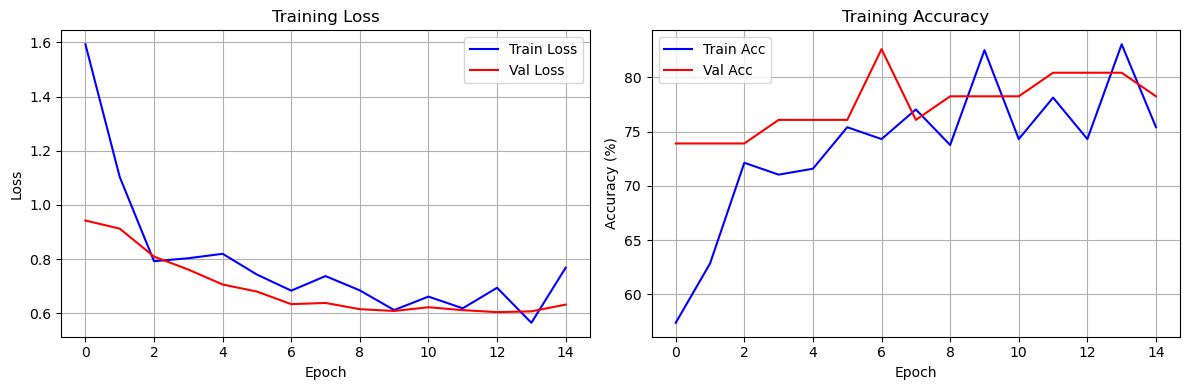

Class distribution:
----------------------------------------
Solid stratus: 9 (3.9%)
Closed MCC: 110 (48.0%)
Open MCC: 48 (21.0%)
Disorganized MCC: 37 (16.2%)
Clustered Cu: 15 (6.6%)
Suppressed Cu: 10 (4.4%)
Model saved to: finetuned_goes_model.pth
Metadata saved to: finetuned_goes_model_metadata.json

Evaluating fine-tuned model:
Loaded 229 samples from labeled_goes_data.nc
Overall Accuracy: 80.79%

Per-class accuracy:
----------------------------------------
Solid stratus: 66.7% (9 samples)
Closed MCC: 90.0% (110 samples)
Open MCC: 89.6% (48 samples)
Disorganized MCC: 64.9% (37 samples)
Clustered Cu: 20.0% (15 samples)
Suppressed Cu: 100.0% (10 samples)


In [56]:
# Example usage of the fine-tuning functions
save_path = 'labeled_goes_data.nc'

# Check if we have labeled data
if os.path.exists(save_path):
    with xr.open_dataset(save_path) as ds:
        num_samples = len(ds.sample)
    print(f"Found {num_samples} labeled samples")
    
    if num_samples >= 5:  # Need at least a few samples
        # Define device
        device_num = '0'  # Change this to your GPU number or 'cpu'
        device = torch.device(f'cuda:{device_num}' if torch.cuda.is_available() and device_num != 'cpu' else 'cpu')
        print(f"Using device: {device}")
        
        # Load the pre-trained modelß
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
        model_path = '/home/jmayer/ACI_research/Code/mesoscale_structure/judge_original/64epochs_accuracy0.91456.pth'
        
        model = timm.create_model('resnet50d', pretrained=False)
        model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
        model.fc = nn.Linear(2048, 6)
        model = model.to(device)
        
        # Load pre-trained weights
        weights = torch.load(model_path, map_location=device)
        model.load_state_dict(weights)
        print("Loaded pre-trained MODIS model")
        
        # Visualize some labeled samples before training
        #print("\nVisualizating labeled samples:")
        #visualize_labeled_data(save_path, num_samples=3)
        
        # Fine-tune the model
        print("Starting fine-tuning...")
        finetuned_model = fine_tune_for_goes(
            model=model,
            labeled_nc_path=save_path,
            num_epochs=15,
            learning_rate=1e-4,
            batch_size=8,  # Small batch size for limited data
            validation_split=0.2
        )
        
        # Save the fine-tuned model
        finetuned_model_path = 'finetuned_goes_model.pth'
        metadata = {
            'model_type': 'ResNet50d fine-tuned for GOES-19',
            'original_model': model_path,
            'training_data': save_path,
            'num_training_samples': num_samples,
            'fine_tuned_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
            'hyperparameters': {
                'learning_rate': 1e-4,
                'batch_size': 8,
                'epochs': 15
            }
        }
        
        save_finetuned_model(finetuned_model, finetuned_model_path, metadata)
        
        # Evaluate the fine-tuned model
        print("\nEvaluating fine-tuned model:")
        evaluate_finetuned_model(finetuned_model, save_path, class_names)
        
    else:
        print("Need at least 5 labeled samples for fine-tuning. Please label more data first.")
else:
    print(f"No labeled data found at {save_path}. Please run the labeling tool first.")

## compare predictions before and after fine-tuning

In [2]:
# evaluate some samples from the labeled dataset
def load_model(model_path):
    """Load the fine-tuned model from disk"""
    device_num = '0'  # Change this to your GPU number or 'cpu'
    device = torch.device(f'cuda:{device_num}' if torch.cuda.is_available() and device_num != 'cpu' else 'cpu')
    
    model = timm.create_model('resnet50d', pretrained=False)
    model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(2048, 6)
    model = model.to(device)
    
    weights = torch.load(model_path, map_location=device)
    model.load_state_dict(weights)
    model.eval()
    
    print(f"Loaded fine-tuned model from {model_path}")
    return model

original_model_path = '/home/jmayer/ACI_research/Code/mesoscale_structure/judge_original/64epochs_accuracy0.91456.pth'
original_model = load_model(original_model_path)

fine_tuned_model_path = 'finetuned_goes_model.pth'
fine_tuned_model = load_model(fine_tuned_model_path)

/tmp/ipykernel_3777350/38303152.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(model_path, map_location=device)


Loaded fine-tuned model from /home/jmayer/ACI_research/Code/mesoscale_structure/judge_original/64epochs_accuracy0.91456.pth
Loaded fine-tuned model from finetuned_goes_model.pth


Loaded 229 samples from labeled_goes_data.nc
tensor([[  0.5727,   9.8814,  -3.5109,  -3.0336,  -5.1723, -13.1780]],
       grad_fn=<AddmmBackward0>)
tensor([[ 4.3160,  6.5746, -6.5324, -0.9200, -3.7857, -9.3485]],
       grad_fn=<AddmmBackward0>)


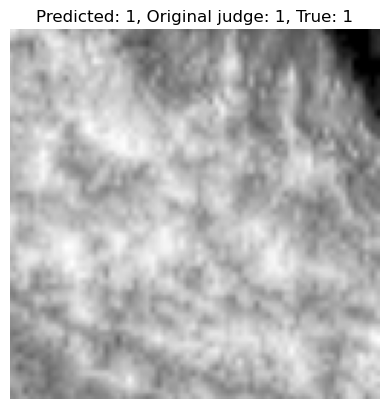

tensor([[-11.7946,   1.5601,  11.8863,   0.7834,   1.9566, -17.4224]],
       grad_fn=<AddmmBackward0>)
tensor([[ -5.0412,  -0.9839,   6.8162,   6.4591,   5.1318, -21.9661]],
       grad_fn=<AddmmBackward0>)


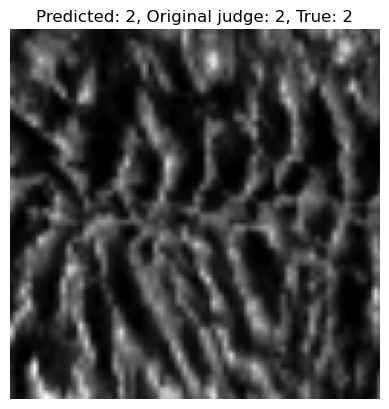

tensor([[ -9.5406,   3.1157,   8.5838,   4.9792,  -1.7867, -18.8359]],
       grad_fn=<AddmmBackward0>)
tensor([[ -4.5076,   1.7722,   4.1611,  11.1934,  -1.0557, -23.4813]],
       grad_fn=<AddmmBackward0>)


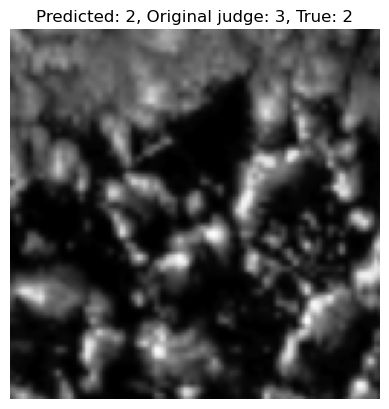

tensor([[-1.6912,  5.2261, -1.8600, -2.2988, -2.5762, -6.7319]],
       grad_fn=<AddmmBackward0>)
tensor([[ 0.5140,  6.5326, -4.0927,  0.3667, -3.0745, -7.7112]],
       grad_fn=<AddmmBackward0>)


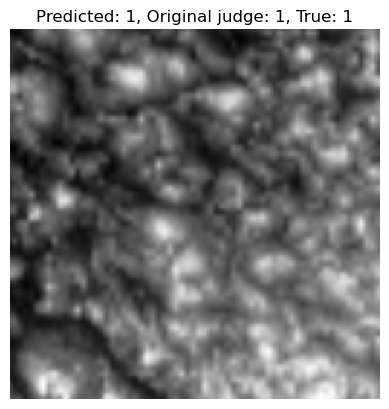

tensor([[ -9.8577,  -1.6499,   8.2181,   1.6282,   1.6976, -11.2522]],
       grad_fn=<AddmmBackward0>)
tensor([[ -4.6267,  -2.3650,   4.2873,  10.6008,   3.1365, -20.0903]],
       grad_fn=<AddmmBackward0>)


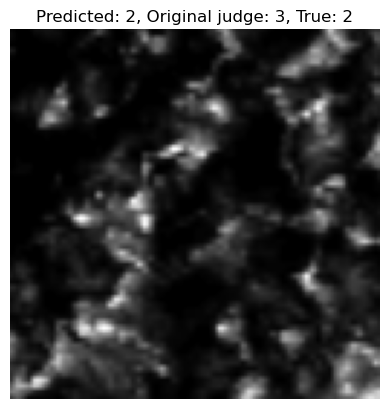

In [13]:
dataset = GOESLabeledDataset(save_path)

for i in np.random.choice(len(dataset), 5, replace=False):
    image_tensor, label_tensor = dataset[i]  # Unpack the tuple correctly

    # Add batch dimension since model expects batched input
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Shape: (1, 4, 128, 128)

    # Now pass only the image tensor to the new model
    outputs = fine_tuned_model(image_tensor)
    _, predicted = torch.max(outputs.data, 1)

    outputs_original = original_model(image_tensor)
    _, predicted_original = torch.max(outputs_original.data, 1)

    plt.imshow(image_tensor[0][3].cpu().numpy(), cmap='Greys_r')
    plt.title(f"Predicted: {predicted.item()}, Original judge: {predicted_original.item()}, True: {label_tensor.item()}")
    plt.axis('off')
    print(outputs)
    print(outputs_original)
    plt.show()